# Multan UHI — Reconstructed Reproducibility Pipeline (CDE Portfolio)

**Musab Shahid | Bahauddin Zakariya University | 2013–2023**

**Provenance:** Reconstructed from archived `fyp.ipynb - Colab Code.pdf` and the original FYP report. This is **not** the original executable notebook. The original vulnerability rules were absent from the PDF, so Section 6 below implements a **new, clearly labeled 2026 relative surface-vulnerability proxy**. Do not represent it as a replication of the original vulnerability classification.

**Verification:** An earlier reconstructed notebook run produced the four CSVs under `data/reconstructed/`. That run reported no saved Python exceptions, and annual index means and K-Means summaries matched historical tables to displayed precision. **This newly organized notebook has not itself been independently executed end-to-end.** It requires Colab, Google Earth Engine access, and compatible datasets.

**Basemap note:** Public OpenStreetMap tiles may be blocked independently of Earth Engine. `SHOW_INTERACTIVE_MAPS = False` by default; numerical analysis is independent of the basemap.


In [1]:
%pip -q install earthengine-api geemap pandas numpy matplotlib scipy

In [2]:
import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from pathlib import Path

PROJECT_ID = "fyp-multan-spatiotemp-analysis"
YEARS = [2013, 2015, 2017, 2018, 2019, 2021, 2023]
SHOW_INTERACTIVE_MAPS = False
OUTPUT_DIR = Path("/content/multan_uhi_reconstructed_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SCALE_M = 30

try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate(auth_mode="colab")
    ee.Initialize(project=PROJECT_ID)
print("GEE initialized:", ee.Number(1).getInfo())
multan_point = ee.Geometry.Point([71.4753, 30.1575])
analysis_aoi = multan_point.buffer(25000)

if SHOW_INTERACTIVE_MAPS:
    m = geemap.Map()
    m.centerObject(multan_point, 10)
    m.addLayer(analysis_aoi, {"color": "cyan"}, "25-km AOI")
    display(m)

GEE initialized: 1


## 1. Source-derived Landsat 8 preprocessing

Dataset: `LANDSAT/LC08/C02/T1_L2`; 25-km radial AOI; May 1 to **exclusive September 30** of each selected year; metadata cloud cover below 10%. This retains the source code's exact date-filter semantics, including exclusion of September 30. Masking and scale factors follow the original PDF; derived indices use `normalizedDifference`, which can mask pixels with negative reflectance.

In [3]:
def mask_landsat_l2(img):
    qa = img.select("QA_PIXEL")
    radsat = img.select("QA_RADSAT")
    mask = (qa.bitwiseAnd(1 << 0).eq(0)
            .And(qa.bitwiseAnd(1 << 1).eq(0))
            .And(qa.bitwiseAnd(1 << 2).eq(0))
            .And(qa.bitwiseAnd(1 << 3).eq(0))
            .And(qa.bitwiseAnd(1 << 4).eq(0))
            .And(qa.bitwiseAnd(1 << 5).eq(0))
            .And(radsat.eq(0)))
    return img.updateMask(mask)

def scale_landsat_l2(img):
    optical = img.select("SR_B[1-7]").multiply(0.0000275).add(-0.2)
    lst = img.select("ST_B10").multiply(0.00341802).add(149).subtract(273.15)
    return img.addBands(optical, overwrite=True).addBands(lst.rename("LST"), overwrite=True)

def add_indices(img):
    return img.addBands([
        img.normalizedDifference(["SR_B5", "SR_B4"]).rename("NDVI"),
        img.normalizedDifference(["SR_B6", "SR_B5"]).rename("NDBI"),
        img.normalizedDifference(["SR_B3", "SR_B6"]).rename("MNDWI")
    ])

def process_year(year):
    collection = (ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
                  .filterBounds(analysis_aoi)
                  .filterDate(f"{year}-05-01", f"{year}-09-30")
                  .filter(ee.Filter.lt("CLOUD_COVER", 10)))
    n = collection.size().getInfo()
    if not n:
        raise ValueError(f"No qualifying Landsat scenes for {year}")
    composite = (collection.map(mask_landsat_l2)
                 .map(scale_landsat_l2).map(add_indices)
                 .median().clip(analysis_aoi))
    return n, composite.select(["LST", "NDVI", "NDBI", "MNDWI"])

images, scene_counts = {}, {}
for year in YEARS:
    scene_counts[year], images[year] = process_year(year)
    print(year, "eligible scenes:", scene_counts[year])

2013 eligible scenes: 12
2015 eligible scenes: 10
2017 eligible scenes: 11
2018 eligible scenes: 12
2019 eligible scenes: 10
2021 eligible scenes: 13
2023 eligible scenes: 9


## 2. Annual surface-temperature and index summaries

Spatial standard deviations describe within-AOI variability; they are **not confidence intervals**. Computations are made on per-year median composites.

In [4]:
def reduce_year_summary(image, year):
    result = image.reduceRegion(
        reducer=ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True),
        geometry=analysis_aoi, scale=SCALE_M,
        bestEffort=True, maxPixels=1e13).getInfo()
    return {"Year": year, **{k: np.nan if v is None else v for k, v in result.items()}}

summary_df = pd.DataFrame(
    [reduce_year_summary(images[y], y) for y in YEARS]
).set_index("Year")
summary_df = summary_df.reindex(columns=[
    "LST_mean", "LST_stdDev", "NDVI_mean", "NDVI_stdDev",
    "NDBI_mean", "NDBI_stdDev", "MNDWI_mean", "MNDWI_stdDev"
])
display(summary_df)
summary_df.to_csv(OUTPUT_DIR / "annual_index_summary.csv")

,LST_mean,LST_stdDev,NDVI_mean,NDVI_stdDev,NDBI_mean,NDBI_stdDev,MNDWI_mean,MNDWI_stdDev
Year,,,,,,,,
2013,40.058257,3.598212,0.342233,0.144020,-0.133491,0.096163,-0.264996,0.080601
2015,41.791820,3.875881,0.352526,0.156743,-0.125926,0.102936,-0.284078,0.120932
2017,41.733344,3.834987,0.397475,0.177153,-0.157339,0.114342,-0.287460,0.099438
2018,41.284017,3.686174,0.313608,0.132880,-0.111748,0.087750,-0.251904,0.070095
2019,41.278346,4.000412,0.351675,0.169978,-0.128438,0.106936,-0.279800,0.112186
2021,39.600956,3.929824,0.370416,0.164258,-0.154833,0.108238,-0.260747,0.092725
2023,40.666286,3.787544,0.370480,0.163704,-0.133389,0.106816,-0.287477,0.097013


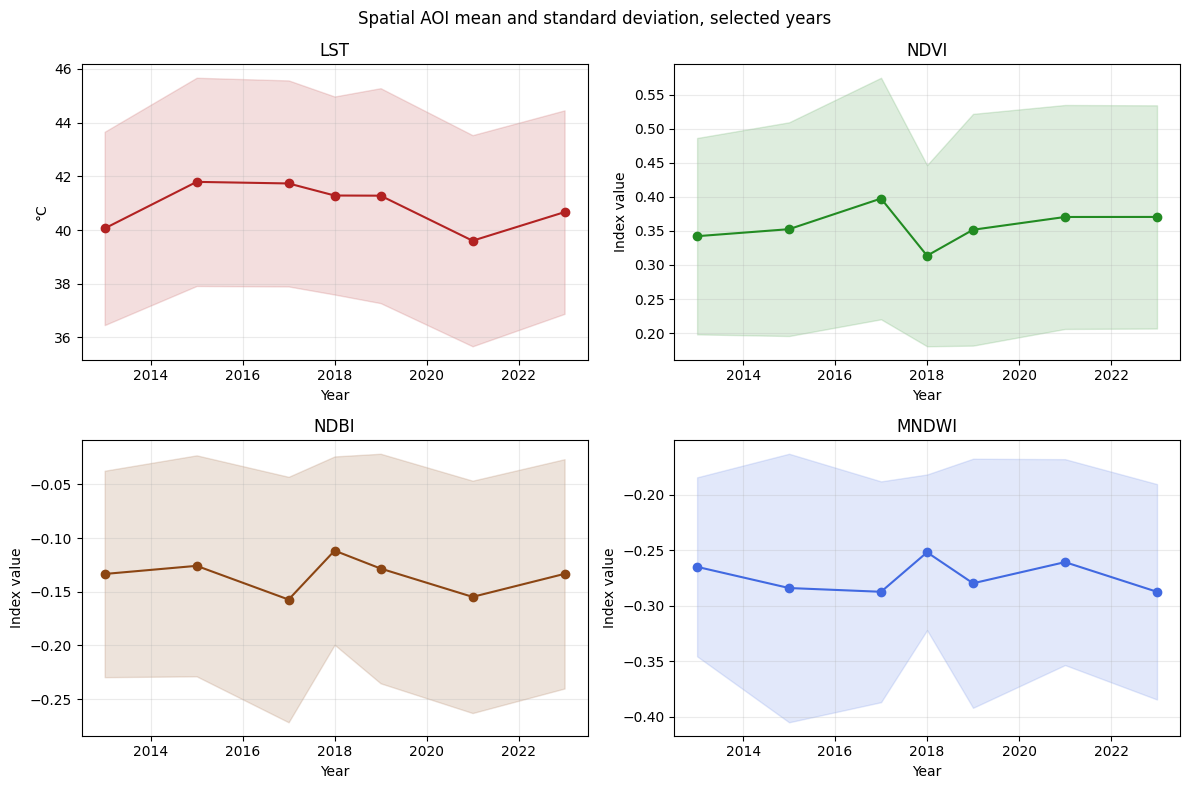

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, key, color in zip(axes.flat, ["LST", "NDVI", "NDBI", "MNDWI"],
                          ["firebrick", "forestgreen", "saddlebrown", "royalblue"]):
    mean, std = summary_df[key + "_mean"], summary_df[key + "_stdDev"]
    ax.plot(summary_df.index, mean, marker="o", color=color)
    ax.fill_between(summary_df.index, mean-std, mean+std, color=color, alpha=0.15)
    ax.set(xlabel="Year", ylabel="°C" if key=="LST" else "Index value", title=key)
    ax.grid(alpha=0.25)
fig.suptitle("Spatial AOI mean and standard deviation, selected years")
fig.tight_layout()
plt.show()

## 3. Optional interactive LST maps and 2013–2023 difference

Map widgets are optional because browser tile access can fail even when GEE is healthy. The simple LST difference does **not** standardize acquisition dates, cloud-observation coverage or weather.

In [6]:
heat_vis = {"min": 25, "max": 50, "palette": ["blue","green","yellow","orange","red"]}
lst_difference = images[2023].select("LST").subtract(images[2013].select("LST"))
if SHOW_INTERACTIVE_MAPS:
    m = geemap.Map()
    m.centerObject(multan_point, 11)
    for year in YEARS:
        m.addLayer(images[year].select("LST"), heat_vis, f"LST {year}", shown=(year == 2023))
    display(m)
    d = geemap.Map()
    d.centerObject(multan_point, 11)
    d.addLayer(lst_difference, {"min":-5,"max":5,"palette":["blue","white","red"]},
               "2023 minus 2013 LST (°C)")
    display(d)
else:
    print("Map widgets skipped: SHOW_INTERACTIVE_MAPS = False")

Map widgets skipped: SHOW_INTERACTIVE_MAPS = False


## 4. Descriptive NDVI–LST regressions

As in the original PDF, the sample excludes NDVI ≤ 0; correlation is observational and affected by spatial autocorrelation, seasonal compositing and other confounding factors.

2013 n 987 R² 0.514
2015 n 978 R² 0.335
2017 n 991 R² 0.246
2018 n 996 R² 0.435
2019 n 980 R² 0.436
2021 n 995 R² 0.447
2023 n 994 R² 0.365


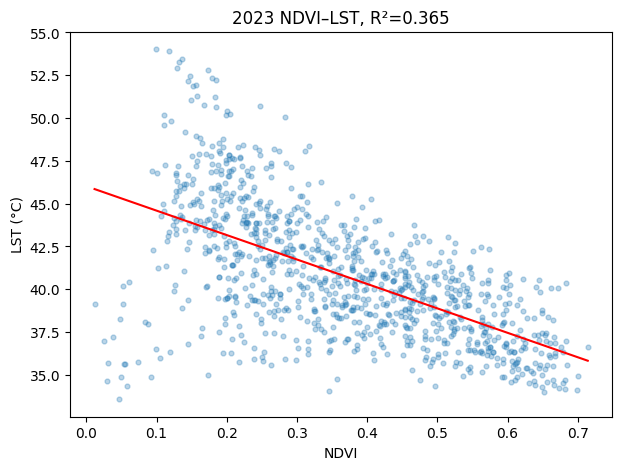

In [7]:
def fit_ndvi_lst(image):
    samples = image.select(["LST", "NDVI"]).sample(
        region=analysis_aoi, scale=SCALE_M, numPixels=1000, seed=42
    ).getInfo()["features"]
    df = pd.DataFrame([f["properties"] for f in samples]).dropna()
    df = df.loc[df["NDVI"] > 0].copy()
    if len(df) < 3 or df.NDVI.nunique() < 2:
        raise ValueError("Insufficient valid sampled values")
    return df, stats.linregress(df.NDVI, df.LST)

regressions = {}
for year in YEARS:
    df, model = fit_ndvi_lst(images[year])
    regressions[year] = (df, model)
    print(year, "n", len(df), "R²", round(model.rvalue**2, 3))
df, model = regressions[2023]
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df.NDVI, df.LST, s=12, alpha=.3)
xx = np.linspace(df.NDVI.min(), df.NDVI.max(), 100)
ax.plot(xx, model.intercept+model.slope*xx, c="red")
ax.set(xlabel="NDVI", ylabel="LST (°C)", title=f"2023 NDVI–LST, R²={model.rvalue**2:.3f}")
plt.show()

## 5. 2023 unsupervised K-Means clusters

Four-band input: LST, NDVI, NDBI, MNDWI; 5,000 training points, nominal 30-m scale, k=4. **No feature standardization or independent land-cover validation was performed in the original workflow**. Cluster IDs can permute; the archive labels (Water, Vegetation, Barren, Urban) remain explicitly **historical and unvalidated**.

In [8]:
stack_2023 = images[2023].select(["LST","NDVI","NDBI","MNDWI"])
training = stack_2023.sample(region=analysis_aoi, scale=SCALE_M,
                             numPixels=5000, seed=42)
clusterer = ee.Clusterer.wekaKMeans(4).train(training)
zones = stack_2023.cluster(clusterer)
rows = []
for cluster_id in range(4):
    mask = zones.eq(cluster_id)
    means = stack_2023.updateMask(mask).reduceRegion(
        reducer=ee.Reducer.mean(), geometry=analysis_aoi,
        scale=SCALE_M, bestEffort=True, maxPixels=1e13).getInfo()
    area = ee.Image.pixelArea().updateMask(mask).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=analysis_aoi,
        scale=SCALE_M, maxPixels=1e13).getInfo().get("area")
    rows.append({"cluster_id": cluster_id, **means, "area_m2": area})
zone_df = pd.DataFrame(rows).set_index("cluster_id")
zone_df["area_proportion"] = zone_df["area_m2"]/zone_df["area_m2"].sum()
zone_df["historical_source_label_unvalidated"] = zone_df.index.map(
    {0:"Water", 1:"Vegetation", 2:"Barren", 3:"Urban"})
display(zone_df)
zone_df.to_csv(OUTPUT_DIR/"kmeans_2023_cluster_summary.csv")
if SHOW_INTERACTIVE_MAPS:
    m = geemap.Map()
    m.centerObject(multan_point,11)
    m.addLayer(zones, {"min":0,"max":3,"palette":["blue","green","yellow","red"]},
               "Unsupervised clusters (unvalidated labels)")
    display(m)

,LST,MNDWI,NDBI,NDVI,area_m2,area_proportion,historical_source_label_unvalidated
cluster_id,,,,,,,
0,36.184340,0.162119,-0.220966,0.055414,6.592899e+07,0.034021,Water
1,37.771099,-0.331808,-0.254346,0.563237,5.965044e+08,0.307809,Vegetation
2,40.032140,-0.305260,-0.119256,0.364606,7.256022e+08,0.374427,Barren
3,45.179920,-0.269874,-0.010361,0.206993,5.498665e+08,0.283743,Urban


## 6. NEW 2026 surface-vulnerability proxy — not the historical model

The original report mentions **high LST, low NDVI and high NDBI**, but the archived PDF contains no definitions for `vul_mask` and `vul_classes_combined`, no thresholds and no scoring formula.

This **new rule** uses the 2023 valid-pixel AOI distributions: LST ≥ 75th percentile, NDVI ≤ 25th percentile, NDBI ≥ 75th percentile. Score 0 = Low, scores 1–2 = Moderate, score 3 = Extreme. It measures a **relative satellite-surface proxy**, **not human heat vulnerability or health risk**. Do not calibrate it to the historical class proportions.

In [10]:
source = images[2023].select(["LST","NDVI","NDBI"])
valid = source.mask().reduce(ee.Reducer.min())
source = source.updateMask(valid)
p = source.reduceRegion(
    reducer=ee.Reducer.percentile([25,75]), geometry=analysis_aoi,
    scale=SCALE_M, maxPixels=1e13, tileScale=4).getInfo()
keys = ("LST_p75","NDVI_p25","NDBI_p75")
if any(p.get(key) is None for key in keys):
    raise RuntimeError(f"Missing threshold statistics: {p}")
print("NEW threshold values:", {k:p[k] for k in keys})
score = (source.select("LST").gte(float(p["LST_p75"]))
         .add(source.select("NDVI").lte(float(p["NDVI_p25"])))
         .add(source.select("NDBI").gte(float(p["NDBI_p75"])))
)
new_classes = (
    score.eq(1).Or(score.eq(2)).multiply(1)
    .add(score.eq(3).multiply(2))
    .rename("vulnerability_class").toInt8().updateMask(valid)
)
if SHOW_INTERACTIVE_MAPS:
    m = geemap.Map()
    m.centerObject(multan_point,11)
    m.addLayer(new_classes, {"min":0,"max":2,
        "palette":["#2a9d8f","#f4a261","#d62828"]},
        "NEW relative vulnerability: Low/Moderate/Extreme")
    display(m)

NEW threshold values: {'LST_p75': 42.93806881055483, 'NDVI_p25': 0.23632396322648935, 'NDBI_p75': -0.0449150966389647}


In [11]:
area_image = ee.Image.pixelArea().rename("area_m2").addBands(new_classes.rename("class"))
groups = area_image.reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1,groupName="class"),
    geometry=analysis_aoi, scale=SCALE_M, maxPixels=1e13, tileScale=4
).getInfo().get("groups",[])
by_class = {int(x["class"]): float(x["sum"]) for x in groups}
total = sum(by_class.values())
if total <= 0:
    raise RuntimeError("No classified valid pixels")
names = {0:"Low",1:"Moderate",2:"Extreme"}
vulnerability_df = pd.DataFrame([
    {"class_code":i,"vulnerability":names[i],"area_km2":by_class.get(i,0)/1e6,
     "percent_of_valid_area":100*by_class.get(i,0)/total}
    for i in range(3)])
assert abs(vulnerability_df.percent_of_valid_area.sum()-100)<1e-6
display(vulnerability_df)
vulnerability_df.to_csv(OUTPUT_DIR/"new_vulnerability_2023_areas.csv",index=False)

,class_code,vulnerability,area_km2,percent_of_valid_area
0,0,Low,1220.240524,62.967090
1,1,Moderate,420.841646,21.716353
2,2,Extreme,296.819886,15.316558


## 7. Comparison with original report (not an equivalence test)

The FYP report lists **Low 38.157724%, Moderate 57.141238%, Extreme 4.701038%**. These came from an unrecovered model, not the new percentile rules. Differences document a change in method; they must not be interpreted as validation failures of the old method.

In [12]:
historic = {"Low":38.157724, "Moderate":57.141238, "Extreme":4.701038}
comparison = vulnerability_df[["vulnerability","percent_of_valid_area"]].copy()
comparison["historical_report_percent"] = comparison.vulnerability.map(historic)
comparison["difference_percentage_points"] = (
    comparison.percent_of_valid_area-comparison.historical_report_percent)
display(comparison)
comparison.to_csv(OUTPUT_DIR/"historical_vs_new_comparison.csv",index=False)
print("CSV outputs saved to:", OUTPUT_DIR)

,vulnerability,percent_of_valid_area,historical_report_percent,difference_percentage_points
0,Low,62.967090,38.157724,24.809366
1,Moderate,21.716353,57.141238,-35.424885
2,Extreme,15.316558,4.701038,10.615520


CSV outputs saved to: /content/multan_uhi_reconstructed_outputs


## 8. Verification and publication notes

- Compare annual means in `data/reconstructed/annual_index_summary.csv` to the printed table.
- Compare cluster means to `data/reconstructed/kmeans_2023_cluster_summary.csv` **after accounting for possible label permutations**.
- Verify Landsat scene/date and mask logic, LST scaling, valid-pixel denominators and sampled assumptions.
- New vulnerability results are separately stored in `data/reconstructed/new_vulnerability_2023_areas.csv`; original report remains untouched.
- Running in another Google account is possible if it has Earth Engine permission. Update `PROJECT_ID` if necessary; **never commit account secrets**.
- Colab output folder is ephemeral; download outputs before a runtime reset.
- A previous notebook ran with no saved Python exceptions, but **this reorganized notebook has not been re-executed independently**.
